## Importando bibliotecas

In [1]:
#Inativando alertas
import os
import logging

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["PYTHONWARNINGS"] = "ignore"

import warnings
warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

import tensorflow as tf
tf.get_logger().setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)
logging.getLogger("tensorflow").setLevel(logging.ERROR)

In [2]:
# Carregamento de dados
from joblib import load, dump
import pandas as pd
import numpy as np

# Estatística
from scipy.stats import chi2_contingency
from scipy.stats import ks_2samp
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu
from scipy.stats import levene

# Graficos
import seaborn as sns
import matplotlib.pyplot as plt

# Classificador
from src.regression import Regression

In [3]:
#Buscando arquivos
os.listdir("../tabelas/tabelas_finais")

['X_train.csv',
 'y_valid.csv',
 'y_train.csv',
 'y_test.csv',
 'X_test.csv',
 'X_valid.csv']

In [4]:
# Importando os dados de treino
df_train = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_train.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_train.csv"),
    ],
    axis=1,
)

df_train.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo
0,2,1,2,2,3,2,1,1,1,1,2,1,0,0,64.0,Sepse
1,2,1,2,2,2,2,2,1,1,1,2,0,0,0,32.0,Sepse
2,2,1,2,2,2,2,1,1,1,1,1,1,0,0,64.0,Sepse
3,2,0,0,2,2,2,1,1,0,1,2,1,0,0,4.0,Sepse
4,1,0,0,0,0,0,0,0,0,0,0,0,1,1,2.0,Ambiental


In [5]:
# Importando os dados de validação
df_valid = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_valid.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_valid.csv"),
    ],
    axis=1,
)

df_valid.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo
0,0,0,2,1,2,2,2,1,1,1,2,1,0,0,4.00,Sepse
1,1,0,1,0,3,1,2,1,0,1,0,0,1,1,2.00,Ambiental
2,0,0,0,1,0,1,1,0,0,0,0,0,1,1,0.50,Ambiental
3,1,1,2,0,0,0,0,0,1,0,0,0,2,1,8.00,Ambiental
4,0,0,0,1,0,0,1,0,0,0,0,0,1,1,0.25,Ambiental


In [6]:
# Importando os dados de teste
df_test = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_test.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_test.csv"),
    ],
    axis=1,
)

df_test.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo
0,0,0,1,1,0,0,0,0,1,0,0,0,2,1,0.5,Ambiental
1,1,0,0,2,1,1,2,1,1,1,1,1,0,0,4.0,Sepse
2,2,1,2,2,3,2,2,1,1,1,2,1,0,1,32.0,Sepse
3,0,0,1,1,0,0,0,0,0,0,0,0,2,1,2.0,Ambiental
4,1,1,0,1,3,2,2,1,1,1,0,1,0,0,4.0,Sepse


## Validação cruzada e busca de hiperparâmetros

# Treino

## Regressão

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__Suport Vector Machine
2. num__Neural Network

--- Status de Cada Atributo no Pipeline ---
         Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                     num__n_OXA              True              False
                     num__n_MBL              True              False
                  num__n_ISAba1              True              False
                    num__n_ESBL              True              False
        num__n_aminoglicosideos              True              False
       num__n_su

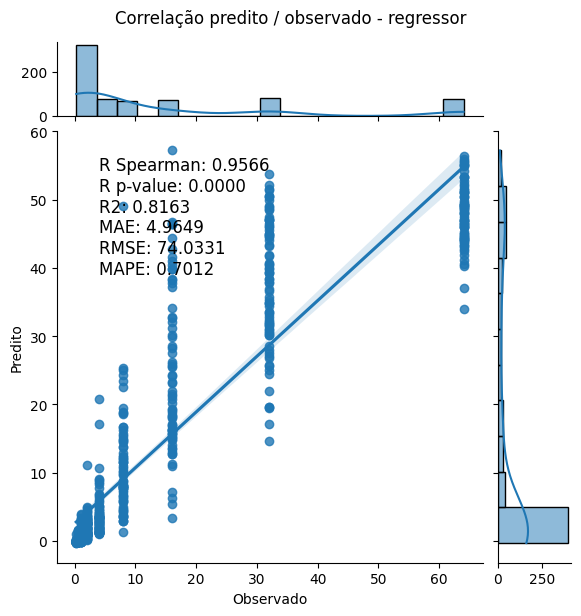

In [35]:
#Criando modelo de regressão
regressor = Regression(df=df_train)
metricas_regr, pred_regr = regressor.regress(modelo="regressor")

## SVM

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
svm__C -> 10
svm__epsilon -> 0.01
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__Suport Vector Machine
2. num__Neural Network

--- Status de Cada Atributo no Pipeline ---
         Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                     num__n_OXA              True              False
                     num__n_MBL              True              False
                  num__n_ISAba1              True              False
                    num__n_ESBL              True              False
        num__n_aminoglicosideos              True              False
       num__n_sulfa_trime

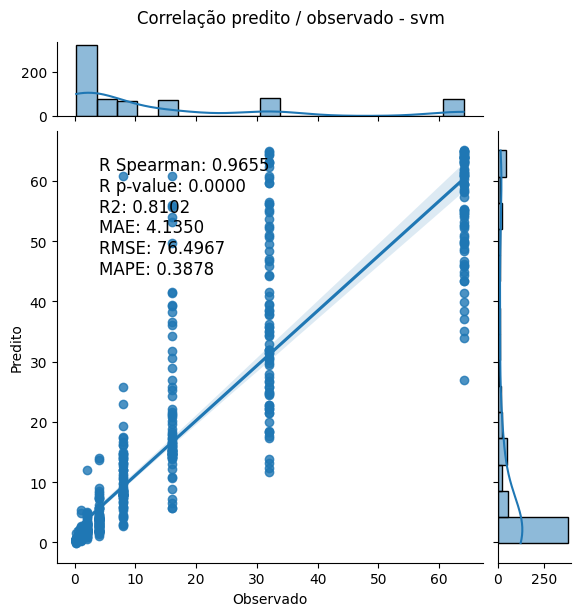

In [36]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

## NB

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
nb__alpha_1 -> 1e-06
nb__lambda_1 -> 0.0001
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__Suport Vector Machine
2. num__Neural Network

--- Status de Cada Atributo no Pipeline ---
         Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                     num__n_OXA              True              False
                     num__n_MBL              True              False
                  num__n_ISAba1              True              False
                    num__n_ESBL              True              False
        num__n_aminoglicosideos              True              False
       num__n_

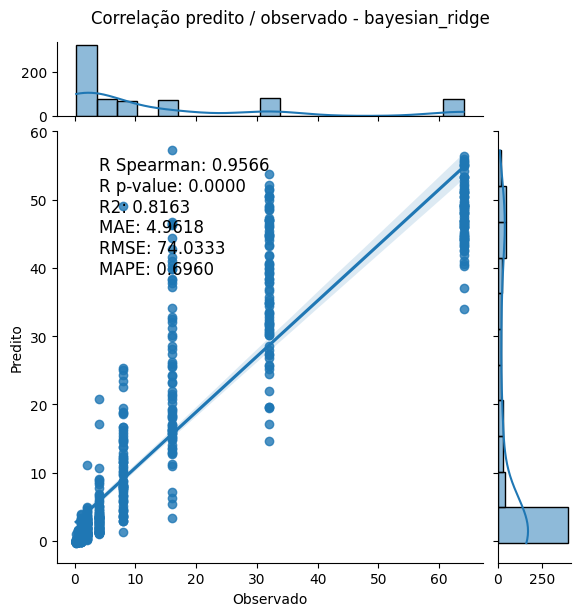

In [37]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

## NN

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.0001
nn__optimizer -> RMSprop
nn__epochs -> 100
nn__batch_size -> 16
nn__activation2 -> relu
nn__activation1 -> relu
feature_selection__k -> 2
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__Suport Vector Machine
2. num__Neural Network

--- Status de Cada Atributo no Pipeline ---
         Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                     num__n_OXA              True              False
                     num__n_MBL              True              False
                  num__n_ISAba1              True              False
                    num__n_ESBL              True              False
        num__n_aminoglicosideos    

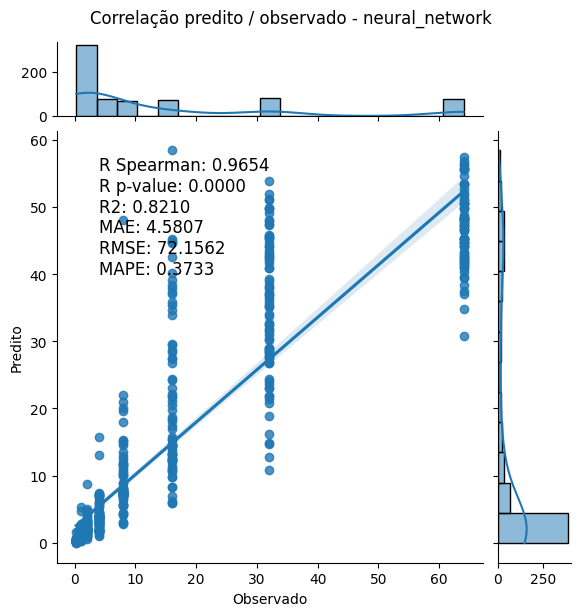

In [38]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=5)

In [39]:
algoritmo_1 = "Multiple Linear Regression"
algoritmo_2 = "Suport Vector Machine"
algoritmo_3 = "Nayve Bayes"
algoritmo_4 = "Neural Network"

# Organizando as métricas de treinamento
df_metricas_valid = pd.concat(
    [
        metricas_regr.T.copy(),
        metricas_svm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_valid.reset_index(inplace=True)
df_metricas_valid["modelo"] = (
    [algoritmo_1] * 6 + [algoritmo_2] * 6 + [algoritmo_3] * 6 + [algoritmo_4] * 6
)
df_metricas_valid.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_valid.head()

,metricas,valores,modelo
0,R Spearman,0.9566,Multiple Linear Regression
1,R p-value,0.0000,Multiple Linear Regression
2,R2,0.8163,Multiple Linear Regression
3,MAE,4.9649,Multiple Linear Regression
4,RMSE,74.0331,Multiple Linear Regression


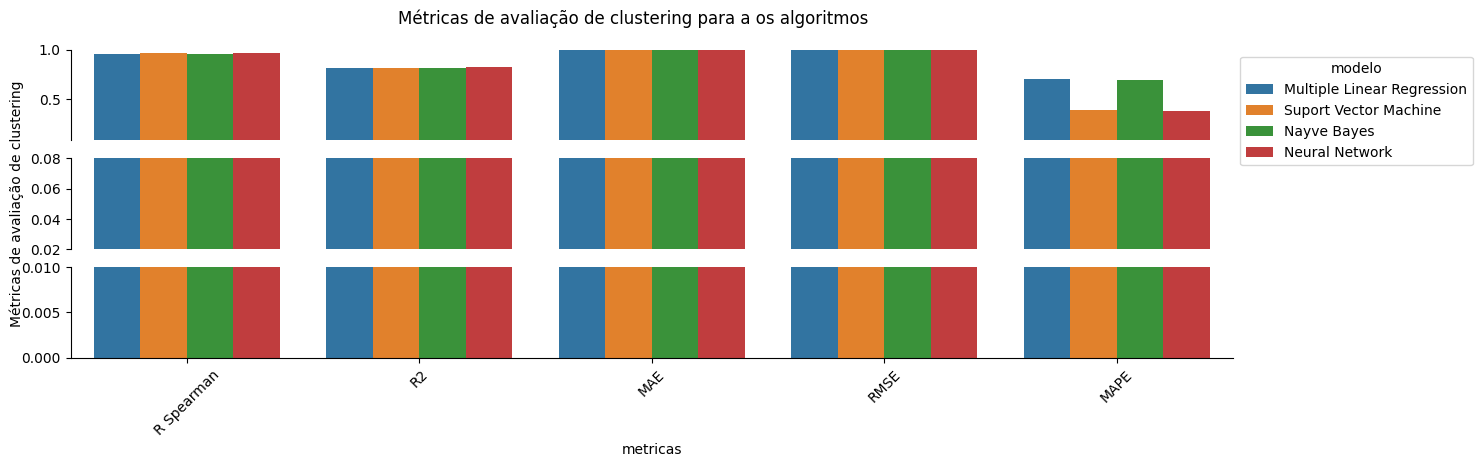

In [40]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(3, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid[df_metricas_valid["metricas"] != "R p-value"],
    ax=ax[0],
)
p.set_ylim(0.08, 1)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
sns.move_legend(ax[0], "upper left", bbox_to_anchor=(1, 1))
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

t = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid[df_metricas_valid["metricas"] != "R p-value"],
    ax=ax[1],
)
t.set_ylim(0.02, 0.08)
t.set(xlabel=None)
t.set_xticks([])
t.spines["bottom"].set_visible(False)
t.spines[["top", "right"]].set_visible(False)
t.get_legend().remove()
t.set_ylabel("Métricas de avaliação de clustering", loc="center")

q = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid[df_metricas_valid["metricas"] != "R p-value"],
    ax=ax[2],
)
q.set(ylabel=None)
q.set_ylim(0, 0.01)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)

plt.show()

In [41]:
df_train[algoritmo_1] = pred_regr.copy()
df_train[algoritmo_2] = pred_svm.copy()
df_train[algoritmo_3] = pred_nb.copy()
df_train[algoritmo_4] = pred_nn.copy()

df_train.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
0,2,1,2,2,3,2,1,1,1,1,2,1,0,0,64.0,Sepse,49.256849,60.915272,49.233315,48.177200
1,2,1,2,2,2,2,2,1,1,1,2,0,0,0,32.0,Sepse,46.182514,52.434438,46.150495,44.239269
2,2,1,2,2,2,2,1,1,1,1,1,1,0,0,64.0,Sepse,52.760226,64.994030,52.746285,52.661625
3,2,0,0,2,2,2,1,1,0,1,2,1,0,0,4.0,Sepse,5.160468,5.645872,5.168638,5.751997
4,1,0,0,0,0,0,0,0,0,0,0,0,1,1,2.0,Ambiental,1.574285,0.634205,1.575684,0.515413


# Validação

## Regressão

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> True
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. cat__grupo_Sepse

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True               True
          

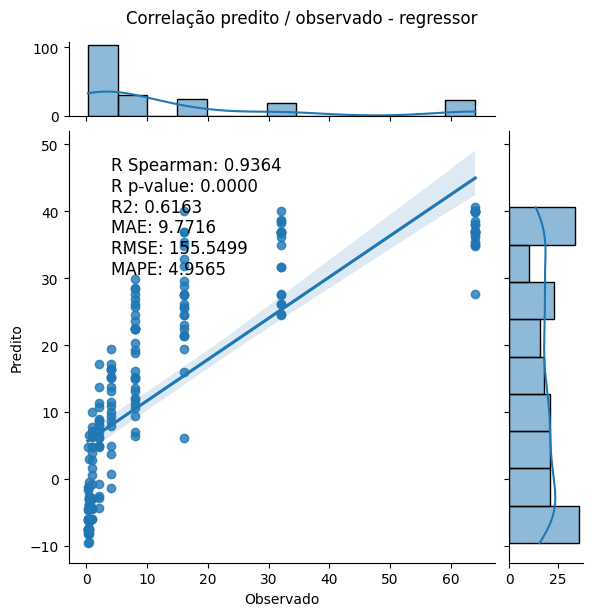

In [43]:
regressor = Regression(df=df_valid)
metricas_regr, pred_regr = regressor.regress(modelo="regressor")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
svm__C -> 10
svm__epsilon -> 0.2
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True               True
                  num__n_MBL              True               True
               num__n_ISAba1              True              False
                 num__n_ESBL              True              False
     num__n_aminoglicosideos              True              False
    num__n_sulfa_trimetoprim              True              False
   

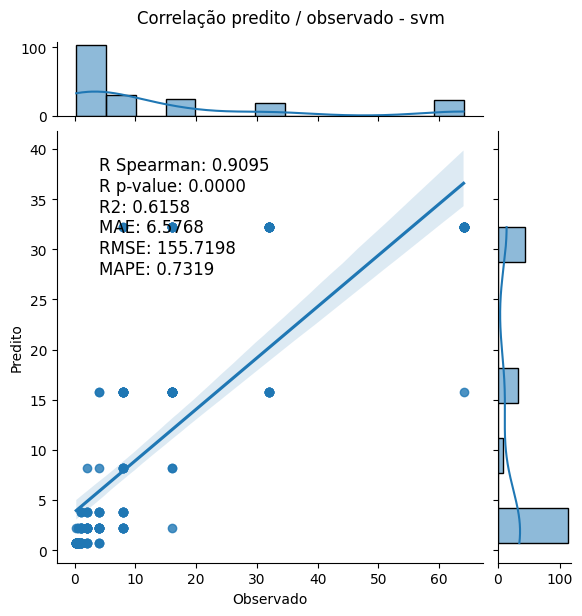

In [44]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True               True
                  num__n_MBL              True               True
               num__n_ISAba1              True              False
                 num__n_ESBL              True              False
     num__n_aminoglicosideos              True              False
    num__n_sulfa_trimetoprim              True           

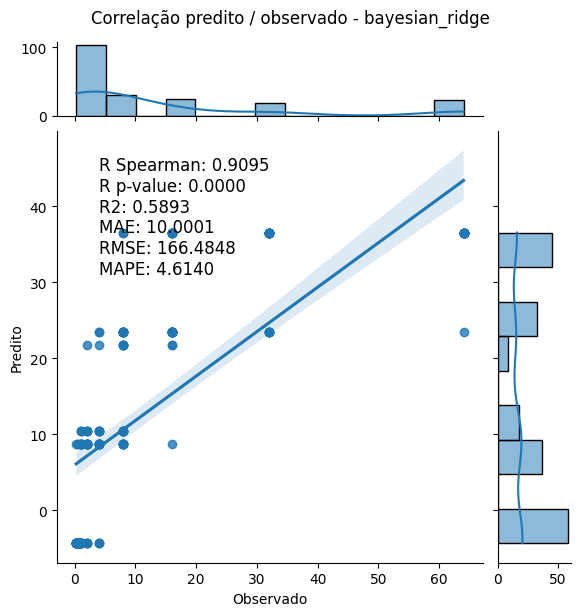

In [45]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.01
nn__optimizer -> SGD
nn__epochs -> 10
nn__batch_size -> 32
nn__activation2 -> tanh
nn__activation1 -> relu
feature_selection__k -> all
Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. cat__grupo_Sepse

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA    

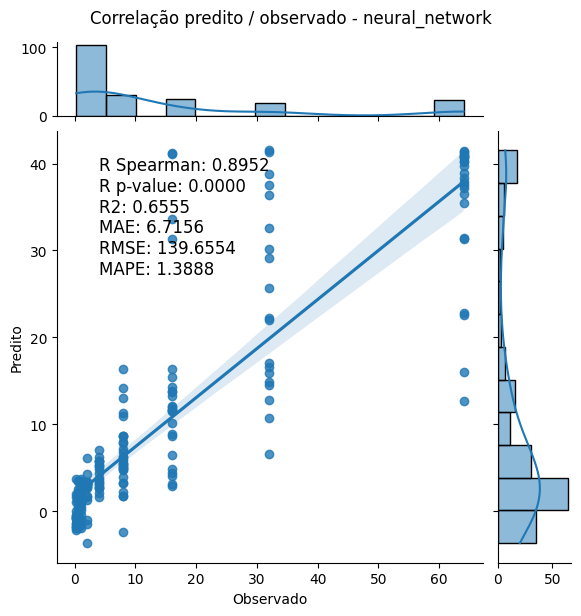

In [46]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=5)

In [47]:
#Organizando as métricas de treinamento
df_metricas_valid = pd.concat(
    [
        metricas_regr.T.copy(),
        metricas_svm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_valid.reset_index(inplace=True)
df_metricas_valid["modelo"] = (
    [algoritmo_1] * 6 + [algoritmo_2] * 6 + [algoritmo_3] * 6 + [algoritmo_4] * 6
)
df_metricas_valid.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_valid.head()

,metricas,valores,modelo
0,R Spearman,0.9364,Multiple Linear Regression
1,R p-value,0.0000,Multiple Linear Regression
2,R2,0.6163,Multiple Linear Regression
3,MAE,9.7716,Multiple Linear Regression
4,RMSE,155.5499,Multiple Linear Regression


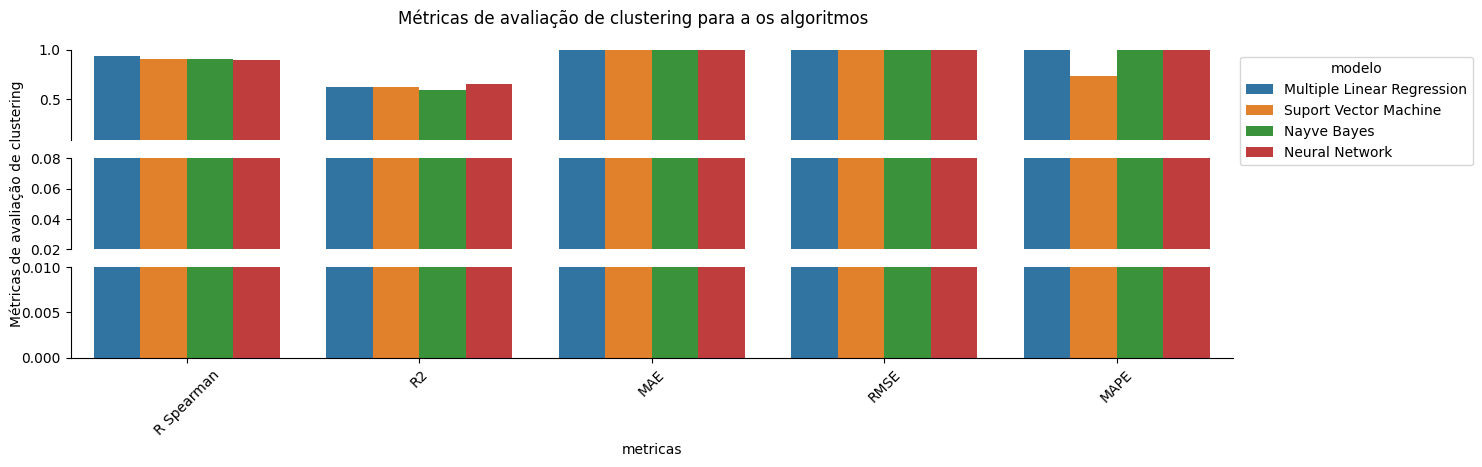

In [49]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(3, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid[df_metricas_valid["metricas"] != "R p-value"],
    ax=ax[0],
)
p.set_ylim(0.08, 1)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
sns.move_legend(ax[0], "upper left", bbox_to_anchor=(1, 1))
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

t = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid[df_metricas_valid["metricas"] != "R p-value"],
    ax=ax[1],
)
t.set_ylim(0.02, 0.08)
t.set(xlabel=None)
t.set_xticks([])
t.spines["bottom"].set_visible(False)
t.spines[["top", "right"]].set_visible(False)
t.get_legend().remove()
t.set_ylabel("Métricas de avaliação de clustering", loc="center")

q = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid[df_metricas_valid["metricas"] != "R p-value"],
    ax=ax[2],
)
q.set(ylabel=None)
q.set_ylim(0, 0.01)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)

plt.show()

In [50]:
df_valid[algoritmo_1] = pred_regr.copy()
df_valid[algoritmo_2] = pred_svm.copy()
df_valid[algoritmo_3] = pred_nb.copy()
df_valid[algoritmo_4] = pred_nn.copy()

df_valid.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
0,0,0,2,1,2,2,2,1,1,1,2,1,0,0,4.00,Sepse,3.789224,0.699974,-4.330786,4.361023
1,1,0,1,0,3,1,2,1,0,1,0,0,1,1,2.00,Ambiental,10.787057,2.200082,8.726469,2.968913
2,0,0,0,1,0,1,1,0,0,0,0,0,1,1,0.50,Ambiental,-6.034086,0.699974,-4.330786,-1.657589
3,1,1,2,0,0,0,0,0,1,0,0,0,2,1,8.00,Ambiental,22.373731,15.799568,23.489134,5.172411
4,0,0,0,1,0,0,1,0,0,0,0,0,1,1,0.25,Ambiental,-6.034086,0.699974,-4.330786,-1.417762


# Teste

## Regressão

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> True
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. cat__grupo_Sepse

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True               True
          

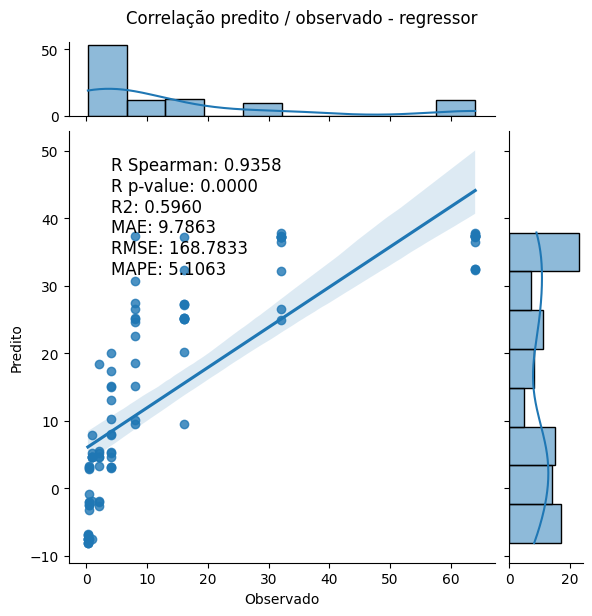

In [61]:
regressor = Regression(df=df_test)
metricas_regr, pred_regr = regressor.regress(modelo="regressor")

## SVM

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
svm__C -> 10
svm__epsilon -> 0.2
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_ISAba1

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True               True
                  num__n_MBL              True              False
               num__n_ISAba1              True               True
                 num__n_ESBL              True              False
     num__n_aminoglicosideos              True              False
    num__n_sulfa_trimetoprim              True              False


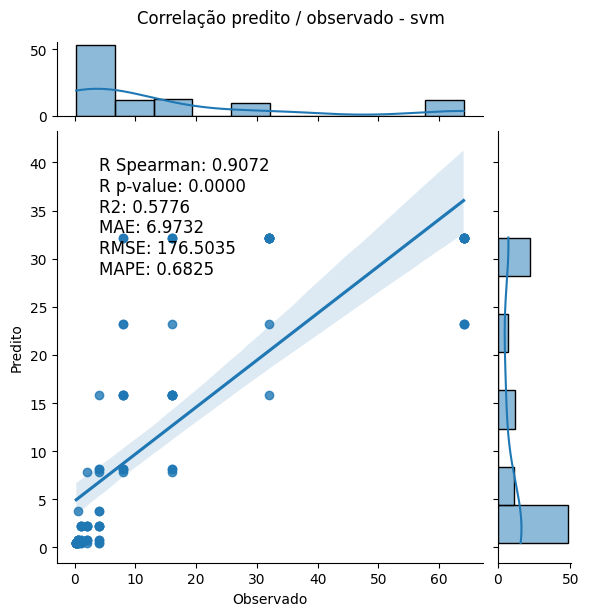

In [62]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

## NB

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
nb__alpha_1 -> 1e-06
nb__lambda_1 -> 0.0001
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_ISAba1

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True               True
                  num__n_MBL              True              False
               num__n_ISAba1              True               True
                 num__n_ESBL              True              False
     num__n_aminoglicosideos              True              False
    num__n_sulfa_trimetoprim              True        

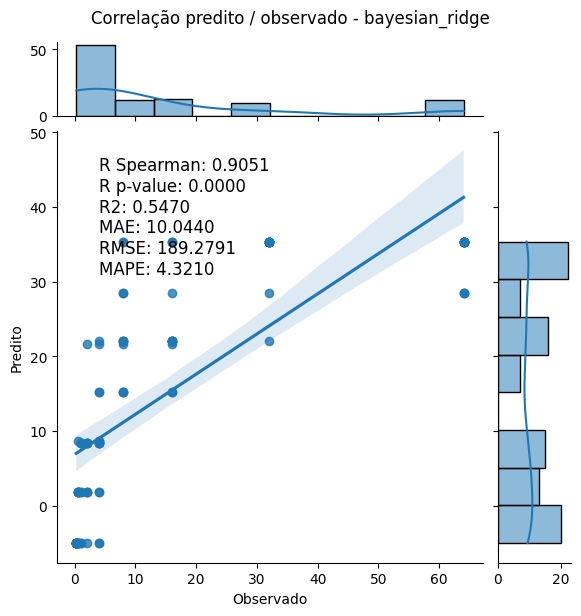

In [63]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

## NN

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.0001
nn__optimizer -> SGD
nn__epochs -> 10
nn__batch_size -> 16
nn__activation2 -> tanh
nn__activation1 -> tanh
feature_selection__k -> all
Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. cat__grupo_Sepse

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA  

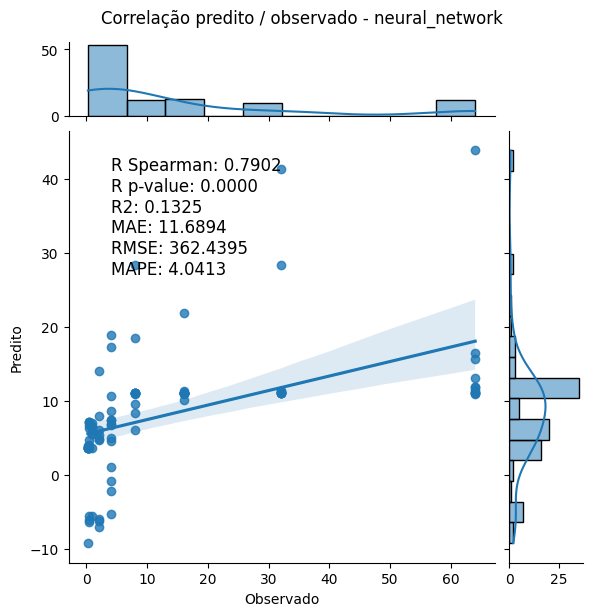

In [64]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=5)

In [69]:
#Organizando as métricas de treinamento
df_metricas_test = pd.concat(
    [
        metricas_regr.T.copy(),
        metricas_svm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_test.reset_index(inplace=True)
df_metricas_test["modelo"] = (
    [algoritmo_1] * 6 + [algoritmo_2] * 6 + [algoritmo_3] * 6 + [algoritmo_4] * 6
)
df_metricas_test.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_test.head()

,metricas,valores,modelo
0,R Spearman,0.9358,Multiple Linear Regression
1,R p-value,0.0000,Multiple Linear Regression
2,R2,0.5960,Multiple Linear Regression
3,MAE,9.7863,Multiple Linear Regression
4,RMSE,168.7833,Multiple Linear Regression


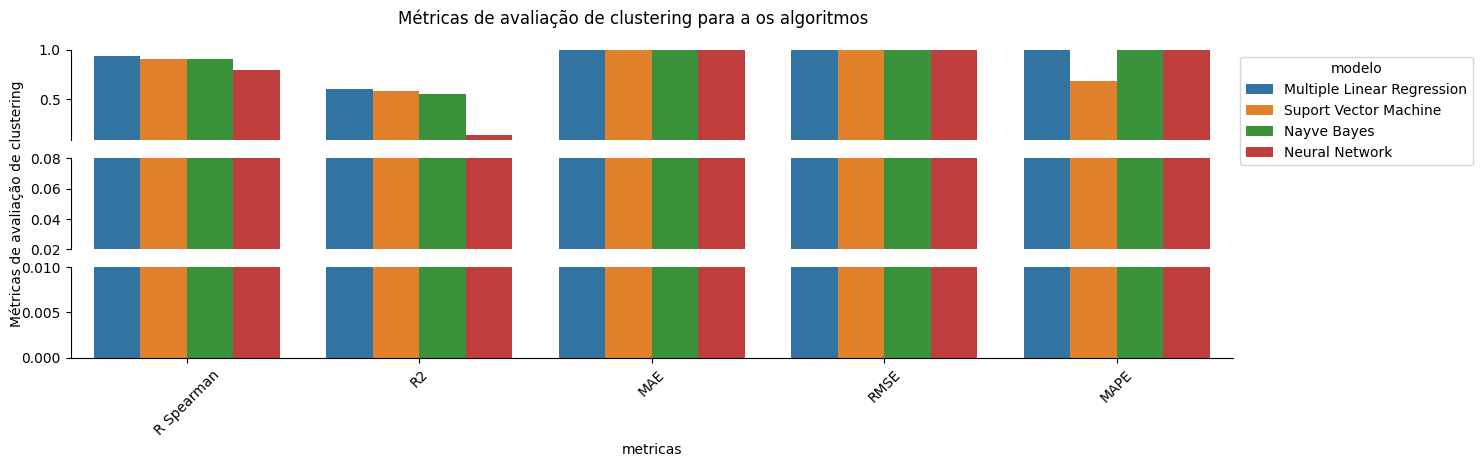

In [70]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(3, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test[df_metricas_test["metricas"] != "R p-value"],
    ax=ax[0],
)
p.set_ylim(0.08, 1)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
sns.move_legend(ax[0], "upper left", bbox_to_anchor=(1, 1))
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

t = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test[df_metricas_test["metricas"] != "R p-value"],
    ax=ax[1],
)
t.set_ylim(0.02, 0.08)
t.set(xlabel=None)
t.set_xticks([])
t.spines["bottom"].set_visible(False)
t.spines[["top", "right"]].set_visible(False)
t.get_legend().remove()
t.set_ylabel("Métricas de avaliação de clustering", loc="center")

q = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test[df_metricas_test["metricas"] != "R p-value"],
    ax=ax[2],
)
q.set(ylabel=None)
q.set_ylim(0, 0.01)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)

plt.show()

In [71]:
df_test[algoritmo_1] = pred_regr.copy()
df_test[algoritmo_2] = pred_svm.copy()
df_test[algoritmo_3] = pred_nb.copy()
df_test[algoritmo_4] = pred_nn.copy()

df_test.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
0,0,0,1,1,0,0,0,0,1,0,0,0,2,1,0.5,Ambiental,-2.029085,0.800036,1.797208,7.170595
1,1,0,0,2,1,1,2,1,1,1,1,1,0,0,4.0,Sepse,5.412327,2.200256,8.323962,0.994906
2,2,1,2,2,3,2,2,1,1,1,2,1,0,1,32.0,Sepse,37.913771,32.199858,35.351248,11.141911
3,0,0,1,1,0,0,0,0,0,0,0,0,2,1,2.0,Ambiental,-2.029085,0.800036,1.797208,5.967117
4,1,1,0,1,3,2,2,1,1,1,0,1,0,0,4.0,Sepse,15.174694,2.200256,8.323962,4.476792


In [73]:
#Organizando as métricas de treinamento
df_metricas_test = pd.concat(
    [
        metricas_regr.T.copy(),
        metricas_svm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_test.reset_index(inplace=True)
df_metricas_test["modelo"] = (
    [algoritmo_1] * 6 + [algoritmo_2] * 6 + [algoritmo_3] * 6 + [algoritmo_4] * 6
)
df_metricas_test.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_test.head()

,metricas,valores,modelo
0,R Spearman,0.9358,Multiple Linear Regression
1,R p-value,0.0000,Multiple Linear Regression
2,R2,0.5960,Multiple Linear Regression
3,MAE,9.7863,Multiple Linear Regression
4,RMSE,168.7833,Multiple Linear Regression


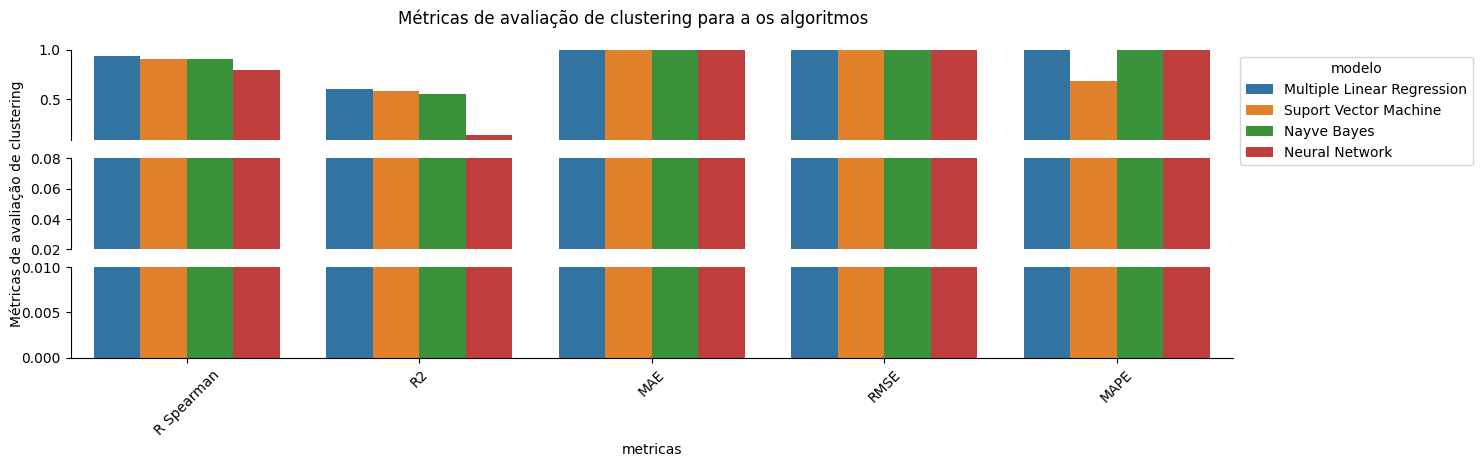

In [74]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(3, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test[df_metricas_test["metricas"] != "R p-value"],
    ax=ax[0],
)
p.set_ylim(0.08, 1)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
sns.move_legend(ax[0], "upper left", bbox_to_anchor=(1, 1))
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

t = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test[df_metricas_test["metricas"] != "R p-value"],
    ax=ax[1],
)
t.set_ylim(0.02, 0.08)
t.set(xlabel=None)
t.set_xticks([])
t.spines["bottom"].set_visible(False)
t.spines[["top", "right"]].set_visible(False)
t.get_legend().remove()
t.set_ylabel("Métricas de avaliação de clustering", loc="center")

q = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test[df_metricas_test["metricas"] != "R p-value"],
    ax=ax[2],
)
q.set(ylabel=None)
q.set_ylim(0, 0.01)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)

plt.show()

In [75]:
df_test[algoritmo_1] = pred_regr.copy()
df_test[algoritmo_2] = pred_svm.copy()
df_test[algoritmo_3] = pred_nb.copy()
df_test[algoritmo_4] = pred_nn.copy()

df_test.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
0,0,0,1,1,0,0,0,0,1,0,0,0,2,1,0.5,Ambiental,-2.029085,0.800036,1.797208,7.170595
1,1,0,0,2,1,1,2,1,1,1,1,1,0,0,4.0,Sepse,5.412327,2.200256,8.323962,0.994906
2,2,1,2,2,3,2,2,1,1,1,2,1,0,1,32.0,Sepse,37.913771,32.199858,35.351248,11.141911
3,0,0,1,1,0,0,0,0,0,0,0,0,2,1,2.0,Ambiental,-2.029085,0.800036,1.797208,5.967117
4,1,1,0,1,3,2,2,1,1,1,0,1,0,0,4.0,Sepse,15.174694,2.200256,8.323962,4.476792


In [76]:
import os
from joblib import dump, load

os.makedirs("./modelo_regr", exist_ok=True)

dump(df_train, "./modelo_regr/df_train_resultados_regression")
df_train = load("./modelo_regr/df_train_resultados_regression")

dump(df_valid, "./modelo_regr/df_valid_resultados_regression")
df_valid = load("./modelo_regr/df_valid_resultados_regression")

dump(df_test, "./modelo_regr/df_test_resultados_regression")
df_test = load("./modelo_regr/df_test_resultados_regression")

In [78]:
#Definindo função de teste de hipótese
def testar_hipotese(y_pred_treino: pd.Series, y_pred_teste: pd.Series) -> None:
    """
    Testa a hipótese de que a distribuição das classes no treino e no teste é estatisticamente igual (homogênea)
    ou diferente (heterogênea) usando o teste Qui-Quadrado.

    Parâmetros:
        y_pred_treino : pd.Series
            Série contendo as previsões do conjunto de treino.
        y_pred_teste : pd.Series
            Série contendo as previsões do conjunto de teste.
    Retorna:
        None
    """

    ks_stat, p_v_ks = ks_2samp(y_pred_treino, y_pred_teste)

    # 1. Teste T de Welch (para médias, assumindo variâncias potencialmente diferentes)
    t_stat, p_val_t = ttest_ind(y_pred_treino, y_pred_teste, equal_var=False)

    # 2. Teste U de Mann-Whitney (para medianas/posição, não-paramétrico)
    u_stat, p_val_u = mannwhitneyu(y_pred_treino, y_pred_teste, alternative="two-sided")

    # 3. Teste de Levene (para variâncias/dispersão)
    w_stat, p_val_levene = levene(y_pred_treino, y_pred_teste)

    # Função auxiliar para imprimir resultados
    def interpretar(nome_teste, p_valor, stat, alfa=0.05):
        resultado = (
            "DIFERENTES (Rejeita H0)"
            if p_valor < alfa
            else "IGUAIS (Falha ao rejeitar H0)"
        )
        print(
            f"{nome_teste:<25} | estatística: {stat:.4f} | p-valor: {p_valor:.4f} | Conclusão: {resultado}"
        )

    print("=== Resultados dos Testes Estatísticos ===\n")
    interpretar("Teste Kolmogorov-Smirnov", p_v_ks, ks_stat)
    interpretar("Teste T (Médias)", p_val_t, t_stat)
    interpretar("Mann-Whitney (Medianas)", p_val_u, u_stat)
    interpretar("Levene (Variâncias)", p_val_levene, w_stat)

    return None

In [ ]:
#Resultado do teste de hipótese Regressão linear
c = -4
print(f"\n\nTestando a hipótese para o modelo: {df_train.columns[c]}")

testar_hipotese(
    y_pred_treino=df_train[df_train.columns[c]],
    y_pred_teste=df_test[df_test.columns[c]],
)



Testando a hipótese para o modelo: Multiple Linear Regression
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.2514 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
Teste T (Médias)          | estatística: -0.4555 | p-valor: 0.6495 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Mann-Whitney (Medianas)   | estatística: 32809.0000 | p-valor: 0.3109 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Levene (Variâncias)       | estatística: 0.3388 | p-valor: 0.5607 | Conclusão: IGUAIS (Falha ao rejeitar H0)


In [80]:
#Resultado do teste de hipótese SVM
c += 1
print(f"\n\nTestando a hipótese para o modelo: {df_train.columns[c]}")
testar_hipotese(
    y_pred_treino=df_train[df_train.columns[c]],
    y_pred_teste=df_test[df_test.columns[c]],
)



Testando a hipótese para o modelo: Suport Vector Machine
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.1929 | p-valor: 0.0026 | Conclusão: DIFERENTES (Rejeita H0)
Teste T (Médias)          | estatística: 1.8596 | p-valor: 0.0646 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Mann-Whitney (Medianas)   | estatística: 34407.0000 | p-valor: 0.7840 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Levene (Variâncias)       | estatística: 2.5694 | p-valor: 0.1093 | Conclusão: IGUAIS (Falha ao rejeitar H0)


In [81]:
#Resultado do teste de hipótese NB
c += 1
print(f"\n\nTestando a hipótese para o modelo: {df_train.columns[c]}")

testar_hipotese(
    y_pred_treino=df_train[df_train.columns[c]],
    y_pred_teste=df_test[df_test.columns[c]],
)



Testando a hipótese para o modelo: Nayve Bayes
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.2829 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
Teste T (Médias)          | estatística: -0.4788 | p-valor: 0.6328 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Mann-Whitney (Medianas)   | estatística: 32338.0000 | p-valor: 0.2182 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Levene (Variâncias)       | estatística: 0.0003 | p-valor: 0.9865 | Conclusão: IGUAIS (Falha ao rejeitar H0)


In [82]:
#NN
c += 1
print(f"\n\nTestando a hipótese para o modelo: {df_train.columns[c]}")

testar_hipotese(
    y_pred_treino=df_train[df_train.columns[c]],
    y_pred_teste=df_test[df_test.columns[c]],
)



Testando a hipótese para o modelo: Neural Network
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.3829 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
Teste T (Médias)          | estatística: 4.6955 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
Mann-Whitney (Medianas)   | estatística: 31254.0000 | p-valor: 0.0831 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Levene (Variâncias)       | estatística: 17.6880 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
